# Phase 7: Model Fine-Tuning with Inverse Class-Weighted Cross-Entropy
This notebook executes hyperparameter optimization for XLM-RoBERTa on Aspect-Based Sentiment Analysis using balanced inverse class frequency weighting to address Neutral class underrepresentation without label smoothing.


In [1]:
import os
import gc
import copy
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, XLMRobertaForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from statsmodels.stats.contingency_tables import mcnemar

import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cuda


In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)


## 1. Data Ingestion, Label Encoding & Tokenization


In [3]:
# Load Datasets
train_df = pd.read_csv('Augmented_Ground_Truth_714.csv')
val_df = pd.read_csv('validation_set_400_final.csv')
test_df = pd.read_csv('test_set_400_final.csv')

# Strict Label Encoding
label2id = {'POSITIVE': 0, 'NEUTRAL': 1, 'NEGATIVE': 2}
id2label = {0: 'POSITIVE', 1: 'NEUTRAL', 2: 'NEGATIVE'}

train_df['encoded_label'] = train_df['sentiment'].astype(str).str.upper().map(label2id)
val_df['encoded_label'] = val_df['sentiment'].astype(str).str.upper().map(label2id)
test_df['encoded_label'] = test_df['sentiment'].astype(str).str.upper().map(label2id)

print(f"Dataset Counts -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")
print("Train Class Distribution:")
print(train_df['sentiment'].value_counts())


Dataset Counts -> Train: 714, Val: 400, Test: 400
Train Class Distribution:
sentiment
POSITIVE    409
NEGATIVE    266
NEUTRAL      39
Name: count, dtype: int64


In [4]:
MODEL_NAME = 'xlm-roberta-base'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class ABSADataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128):
        self.encodings = tokenizer(
            df['TargetAspect'].astype(str).tolist(),
            df['sentence'].astype(str).tolist(),
            truncation=True,
            padding=True,
            max_length=max_length,
            return_tensors='pt'
        )
        self.labels = torch.tensor(df['encoded_label'].tolist(), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

train_dataset = ABSADataset(train_df, tokenizer)
val_dataset = ABSADataset(val_df, tokenizer)
test_dataset = ABSADataset(test_df, tokenizer)
print("Datasets tokenized and converted to PyTorch Datasets.")


Datasets tokenized and converted to PyTorch Datasets.


## 2. Calculate and Format Class Weights
Compute balanced inverse class frequencies using the 714-row training partition with explicit label indexing (`[0, 1, 2]`).


In [5]:
y_train = train_df['encoded_label'].values

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=y_train
)

weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Calculated Balanced Class Weights:")
for idx, name in id2label.items():
    print(f"  Class {idx} ({name}): {weights_tensor[idx].item():.4f}")

# Loss Function with Weighted Cross-Entropy and No Label Smoothing
loss_fn = nn.CrossEntropyLoss(weight=weights_tensor, label_smoothing=0.0)
print(f"Loss Function Initialized: {loss_fn} (label_smoothing=0.0)")


Calculated Balanced Class Weights:
  Class 0 (POSITIVE): 0.5819
  Class 1 (NEUTRAL): 6.1026
  Class 2 (NEGATIVE): 0.8947
Loss Function Initialized: CrossEntropyLoss() (label_smoothing=0.0)


## 3. Architectural Safeguards
Freeze the token embedding layer and lower six encoder layers (Layers 0 to 5) while keeping dropout at 0.1.


In [6]:
def build_constrained_model():
    model = XLMRobertaForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3,
        id2label=id2label,
        label2id=label2id,
        hidden_dropout_prob=0.1,
        attention_probs_dropout_prob=0.1
    ).to(device)

    # Layer Freezing: Embeddings + bottom 6 transformer layers
    for param in model.roberta.embeddings.parameters():
        param.requires_grad = False
    for i in range(6):
        for param in model.roberta.encoder.layer[i].parameters():
            param.requires_grad = False

    return model

sample_model = build_constrained_model()
total_params = sum(p.numel() for p in sample_model.parameters())
trainable_params = sum(p.numel() for p in sample_model.parameters() if p.requires_grad)
frozen_params = total_params - trainable_params
print(f"Total Parameters: {total_params:,}")
print(f"Frozen Parameters: {frozen_params:,} (Embeddings + Layers 0-5)")
print(f"Trainable Parameters: {trainable_params:,} (Layers 6-11 + Classifier Head)")
del sample_model
torch.cuda.empty_cache()
gc.collect()


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total Parameters: 278,045,955
Frozen Parameters: 234,925,824 (Embeddings + Layers 0-5)
Trainable Parameters: 43,120,131 (Layers 6-11 + Classifier Head)


1616

## 4. Hyperparameter Grid Search
Testing batch sizes `[16, 32]` and learning rates `[2e-5, 3e-5, 5e-5]` for 5 epochs with 10% linear warmup.


In [7]:
BATCH_SIZES = [16, 32]
LEARNING_RATES = [2e-5, 3e-5, 5e-5]
EPOCHS = 5
WEIGHT_DECAY = 0.1

grid_records = []
best_overall_f1 = -1.0
best_overall_state = None
best_overall_params = {}
best_overall_history = None

print(f"Starting Hyperparameter Grid Search ({len(BATCH_SIZES) * len(LEARNING_RATES)} combinations)...\n")

for bs in BATCH_SIZES:
    for lr in LEARNING_RATES:
        print(f"============================================================")
        print(f"Testing Config -> Batch Size: {bs} | Learning Rate: {lr}")
        print(f"============================================================")

        set_seed(42)
        gs_train_loader = DataLoader(train_dataset, batch_size=bs, shuffle=True)
        gs_val_loader = DataLoader(val_dataset, batch_size=bs, shuffle=False)

        model = build_constrained_model()
        optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=WEIGHT_DECAY)

        total_steps = len(gs_train_loader) * EPOCHS
        warmup_steps = int(0.1 * total_steps)
        scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

        trial_history = {'train_loss': [], 'val_loss': [], 'val_macro_f1': []}
        trial_best_f1 = -1.0
        trial_best_state = None

        for epoch in range(1, EPOCHS + 1):
            model.train()
            running_train_loss = 0.0

            for batch in gs_train_loader:
                optimizer.zero_grad()
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)

                outputs = model(input_ids, attention_mask=attention_mask)
                loss = loss_fn(outputs.logits, labels)
                loss.backward()

                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                scheduler.step()
                running_train_loss += loss.item()

            epoch_train_loss = running_train_loss / len(gs_train_loader)

            model.eval()
            running_val_loss = 0.0
            val_preds_list, val_true_list = [], []

            with torch.no_grad():
                for batch in gs_val_loader:
                    input_ids = batch['input_ids'].to(device)
                    attention_mask = batch['attention_mask'].to(device)
                    labels = batch['labels'].to(device)

                    outputs = model(input_ids, attention_mask=attention_mask)
                    loss = loss_fn(outputs.logits, labels)
                    running_val_loss += loss.item()

                    preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
                    val_preds_list.extend(preds)
                    val_true_list.extend(labels.cpu().numpy())

            epoch_val_loss = running_val_loss / len(gs_val_loader)
            epoch_val_f1 = f1_score(val_true_list, val_preds_list, average='macro', zero_division=0)

            trial_history['train_loss'].append(epoch_train_loss)
            trial_history['val_loss'].append(epoch_val_loss)
            trial_history['val_macro_f1'].append(epoch_val_f1)

            print(f"  Epoch {epoch}/{EPOCHS} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Macro-F1: {epoch_val_f1:.4f}")

            if epoch_val_f1 > trial_best_f1:
                trial_best_f1 = epoch_val_f1
                trial_best_state = copy.deepcopy(model.state_dict())

        grid_records.append({
            'Batch Size': bs,
            'Learning Rate': lr,
            'Epochs': EPOCHS,
            'Peak Val Macro-F1': trial_best_f1
        })

        if trial_best_f1 > best_overall_f1:
            best_overall_f1 = trial_best_f1
            best_overall_state = trial_best_state
            best_overall_params = {'batch_size': bs, 'learning_rate': lr}
            best_overall_history = copy.deepcopy(trial_history)
            print(f"  -> NEW BEST GRID CONFIGURATION: BS={bs}, LR={lr} with Macro-F1={best_overall_f1:.4f}")

        # Explicitly flush VRAM
        del model, optimizer, scheduler, gs_train_loader, gs_val_loader
        torch.cuda.empty_cache()
        gc.collect()

gs_summary_df = pd.DataFrame(grid_records).sort_values(by='Peak Val Macro-F1', ascending=False).reset_index(drop=True)
print("\n================ GRID SEARCH COMPLETE ================")
print(f"Optimal Parameters: {best_overall_params} with Peak Val Macro-F1: {best_overall_f1:.4f}")
display(gs_summary_df)


Starting Hyperparameter Grid Search (6 combinations)...

Testing Config -> Batch Size: 16 | Learning Rate: 2e-05


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1/5 | Train Loss: 1.0554 | Val Loss: 1.0837 | Val Macro-F1: 0.3289
  Epoch 2/5 | Train Loss: 0.8583 | Val Loss: 1.1692 | Val Macro-F1: 0.3592
  Epoch 3/5 | Train Loss: 0.6295 | Val Loss: 1.2493 | Val Macro-F1: 0.4736
  Epoch 4/5 | Train Loss: 0.5027 | Val Loss: 1.4690 | Val Macro-F1: 0.4504
  Epoch 5/5 | Train Loss: 0.4871 | Val Loss: 1.5432 | Val Macro-F1: 0.4606
  -> NEW BEST GRID CONFIGURATION: BS=16, LR=2e-05 with Macro-F1=0.4736
Testing Config -> Batch Size: 16 | Learning Rate: 3e-05


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

  Epoch 1/5 | Train Loss: 1.1018 | Val Loss: 1.0695 | Val Macro-F1: 0.2937
  Epoch 2/5 | Train Loss: 0.8439 | Val Loss: 1.1125 | Val Macro-F1: 0.3229
  Epoch 3/5 | Train Loss: 0.6905 | Val Loss: 1.1842 | Val Macro-F1: 0.4508
  Epoch 4/5 | Train Loss: 0.5484 | Val Loss: 1.2172 | Val Macro-F1: 0.4178
  Epoch 5/5 | Train Loss: 0.5009 | Val Loss: 1.2438 | Val Macro-F1: 0.4551
Testing Config -> Batch Size: 32 | Learning Rate: 5e-05


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1/5 | Train Loss: 1.0804 | Val Loss: 1.1137 | Val Macro-F1: 0.3116
  Epoch 2/5 | Train Loss: 0.7751 | Val Loss: 1.1901 | Val Macro-F1: 0.3230
  Epoch 3/5 | Train Loss: 0.6549 | Val Loss: 1.0384 | Val Macro-F1: 0.3766
  Epoch 4/5 | Train Loss: 0.5481 | Val Loss: 1.4063 | Val Macro-F1: 0.4201
  Epoch 5/5 | Train Loss: 0.4727 | Val Loss: 1.4613 | Val Macro-F1: 0.4137

================ GRID SEARCH COMPLETE ================
Optimal Parameters: {'batch_size': 16, 'learning_rate': 2e-05} with Peak Val Macro-F1: 0.4736


,Batch Size,Learning Rate,Epochs,Peak Val Macro-F1
0,16,0.00002,5,0.473630
1,32,0.00003,5,0.455092
2,16,0.00005,5,0.454746
3,16,0.00003,5,0.453645
4,32,0.00005,5,0.420121
5,32,0.00002,5,0.403029


## 5. Checkpoint Preservation & Calibrated Model Setup


In [8]:
SAVE_DIR = "xlmr_absa_weighted"
os.makedirs(SAVE_DIR, exist_ok=True)

# Instantiate model with optimal structure and restore best state dict
calibrated_model = build_constrained_model()
calibrated_model.load_state_dict(best_overall_state)
calibrated_model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
calibrated_model.eval()

print(f"Best model state successfully saved to './{SAVE_DIR}'")


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model state successfully saved to './xlmr_absa_weighted'


## 6. Results and Discussion: Training Dynamics & Validation Performance
Analysis of Cross-Entropy Loss (train vs. validation) and Validation Macro-F1 progression for the optimal hyperparameter configuration.


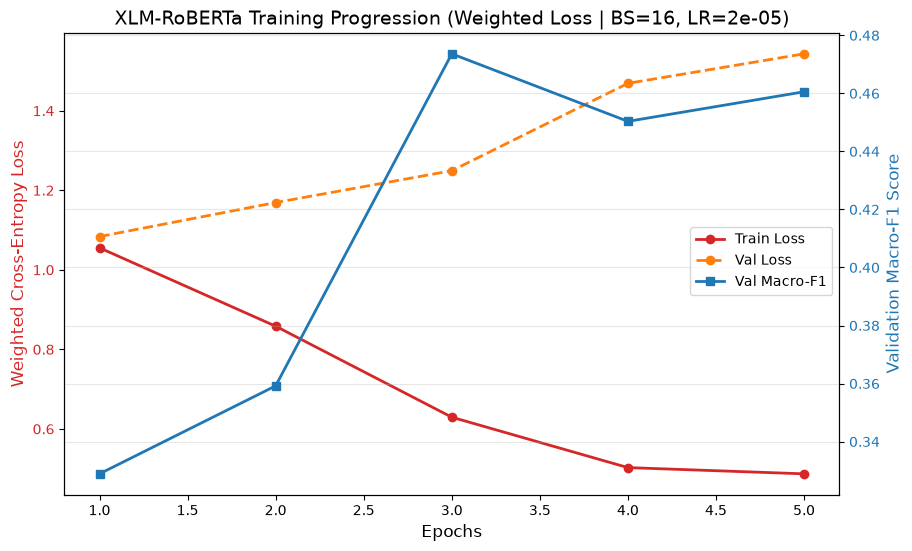

=== XLM-RoBERTa Validation Classification Performance ===
              precision    recall  f1-score   support

    POSITIVE     0.7951    0.8094    0.8021       278
     NEUTRAL     0.1667    0.3182    0.2188        22
    NEGATIVE     0.4667    0.3500    0.4000       100

    accuracy                         0.6675       400
   macro avg     0.4761    0.4925    0.4736       400
weighted avg     0.6784    0.6675    0.6695       400



In [9]:
epochs_range = range(1, EPOCHS + 1)
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.set_xlabel('Epochs', fontsize=12)
ax1.set_ylabel('Weighted Cross-Entropy Loss', color='tab:red', fontsize=12)
ax1.plot(epochs_range, best_overall_history['train_loss'], label='Train Loss', color='tab:red', marker='o', linewidth=2)
ax1.plot(epochs_range, best_overall_history['val_loss'], label='Val Loss', color='tab:orange', marker='o', linestyle='dashed', linewidth=2)
ax1.tick_params(axis='y', labelcolor='tab:red')

ax2 = ax1.twinx()
ax2.set_ylabel('Validation Macro-F1 Score', color='tab:blue', fontsize=12)
ax2.plot(epochs_range, best_overall_history['val_macro_f1'], label='Val Macro-F1', color='tab:blue', marker='s', linewidth=2)
ax2.tick_params(axis='y', labelcolor='tab:blue')

plt.title(f"XLM-RoBERTa Training Progression (Weighted Loss | BS={best_overall_params['batch_size']}, LR={best_overall_params['learning_rate']})", fontsize=14)
fig.legend(loc="center right", bbox_to_anchor=(0.9, 0.5))
plt.grid(True, alpha=0.3)
plt.show()

# Validation Set Full Classification Report on Best Model
val_loader_eval = DataLoader(val_dataset, batch_size=best_overall_params['batch_size'], shuffle=False)
val_eval_preds = []
val_eval_true = []

with torch.no_grad():
    for batch in val_loader_eval:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        outputs = calibrated_model(input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
        val_eval_preds.extend(preds)
        val_eval_true.extend(labels.cpu().numpy())

val_report = classification_report(
    val_eval_true,
    val_eval_preds,
    target_names=["POSITIVE", "NEUTRAL", "NEGATIVE"],
    digits=4
)
print("=== XLM-RoBERTa Validation Classification Performance ===")
print(val_report)


## 7. Baseline Benchmarking (VADER & Tuned SVM TF-IDF)


In [10]:
# 1. VADER Lexicon Baseline
nltk.download('vader_lexicon', quiet=True)
sia = SentimentIntensityAnalyzer()

def predict_vader(text):
    score = sia.polarity_scores(str(text))['compound']
    if score >= 0.05:
        return 0   # POSITIVE
    elif score <= -0.05:
        return 2   # NEGATIVE
    else:
        return 1   # NEUTRAL

test_df['vader_pred'] = test_df['sentence'].apply(predict_vader)

# 2. Aspect-Conditioned SVM TF-IDF with 5-Fold Cross Validation
train_inputs_svm = train_df['TargetAspect'].astype(str) + " " + train_df['sentence'].astype(str)
test_inputs_svm = test_df['TargetAspect'].astype(str) + " " + test_df['sentence'].astype(str)

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('svm', SVC(kernel='linear', random_state=42))
])

param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__max_features': [3000, 5000],
    'svm__C': [0.1, 1.0, 10.0],
    'svm__class_weight': [None, 'balanced']
}

print("Tuning Aspect-Conditioned SVM Baseline...")
grid_svm = GridSearchCV(pipeline, param_grid, cv=5, scoring='f1_macro', n_jobs=-1)
grid_svm.fit(train_inputs_svm, train_df['encoded_label'])

print(f"Optimal SVM Parameters: {grid_svm.best_params_}")
print(f"Best CV Macro-F1: {grid_svm.best_score_:.4f}")

test_df['svm_pred'] = grid_svm.predict(test_inputs_svm)


Tuning Aspect-Conditioned SVM Baseline...
Optimal SVM Parameters: {'svm__C': 10.0, 'svm__class_weight': None, 'tfidf__max_features': 3000, 'tfidf__ngram_range': (1, 1)}
Best CV Macro-F1: 0.6026


## 8. Final Benchmark Metrics, Confusion Matrix & McNemar's Test


In [11]:
test_loader_final = DataLoader(test_dataset, batch_size=32, shuffle=False)
xlmr_test_preds = []
true_test_labels = test_df['encoded_label'].tolist()

calibrated_model.eval()
with torch.no_grad():
    for batch in test_loader_final:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        outputs = calibrated_model(input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
        xlmr_test_preds.extend(preds)

test_df['xlmr_pred'] = xlmr_test_preds

# Benchmark Metrics Compilation
benchmark_models = {
    'VADER': test_df['vader_pred'],
    'SVM (TF-IDF)': test_df['svm_pred'],
    'XLM-RoBERTa (Weighted)': test_df['xlmr_pred']
}

benchmark_rows = []
for name, preds in benchmark_models.items():
    f1_class = f1_score(true_test_labels, preds, average=None, zero_division=0)
    benchmark_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(true_test_labels, preds),
        'Precision (Macro)': precision_score(true_test_labels, preds, average='macro', zero_division=0),
        'Recall (Macro)': recall_score(true_test_labels, preds, average='macro', zero_division=0),
        'Macro-F1': f1_score(true_test_labels, preds, average='macro', zero_division=0),
        'F1 (POS)': f1_class[0],
        'F1 (NEU)': f1_class[1],
        'F1 (NEG)': f1_class[2]
    })

benchmark_df = pd.DataFrame(benchmark_rows).round(4)
print("=== FINAL BENCHMARK METRICS ===")
display(benchmark_df)


=== FINAL BENCHMARK METRICS ===


,Model,Accuracy,Precision (Macro),Recall (Macro),Macro-F1,F1 (POS),F1 (NEU),F1 (NEG)
0,VADER,0.6875,0.5685,0.5052,0.4985,0.8293,0.2034,0.4630
1,SVM (TF-IDF),0.7300,0.5123,0.5290,0.5187,0.8502,0.1875,0.5185
2,XLM-RoBERTa (Weighted),0.7975,0.5873,0.6085,0.5967,0.9043,0.2319,0.6538


In [12]:
# McNemar's Statistical Significance Test
def compute_mcnemar(base_preds):
    b = sum((x == t) and (b != t) for x, b, t in zip(test_df['xlmr_pred'], base_preds, true_test_labels))
    c = sum((x != t) and (b == t) for x, b, t in zip(test_df['xlmr_pred'], base_preds, true_test_labels))
    table = [[0, c], [b, 0]]
    res = mcnemar(table, exact=False, correction=False)
    return b, c, res.statistic, res.pvalue

vader_b, vader_c, vader_chi, vader_p = compute_mcnemar(test_df['vader_pred'])
svm_b, svm_c, svm_chi, svm_p = compute_mcnemar(test_df['svm_pred'])

mcnemar_df = pd.DataFrame([
    {
        'Baseline': 'VADER Lexicon',
        'XLM-R Correct (b)': vader_b,
        'Base Correct (c)': vader_c,
        'Chi-Square': round(vader_chi, 4),
        'p-value': f"{vader_p:.4e}"
    },
    {
        'Baseline': 'SVM (TF-IDF)',
        'XLM-R Correct (b)': svm_b,
        'Base Correct (c)': svm_c,
        'Chi-Square': round(svm_chi, 4),
        'p-value': f"{svm_p:.4e}"
    }
])

print("=== MCNEMAR'S STATISTICAL TEST RESULTS ===")
display(mcnemar_df)


=== MCNEMAR'S STATISTICAL TEST RESULTS ===


,Baseline,XLM-R Correct (b),Base Correct (c),Chi-Square,p-value
0,VADER Lexicon,76,32,17.9259,2.2967e-05
1,SVM (TF-IDF),48,21,10.5652,1.1524e-03


In [13]:
pdf_path = "Phase7_Weighted_Final_Results.pdf"
with PdfPages(pdf_path) as pdf:
    # Page 1: Training Progression Curve
    fig_loss, ax1 = plt.subplots(figsize=(10, 6))
    ax1.set_xlabel('Epochs', fontsize=12)
    ax1.set_ylabel('Weighted Cross-Entropy Loss', color='tab:red', fontsize=12)
    ax1.plot(epochs_range, best_overall_history['train_loss'], label='Train Loss', color='tab:red', marker='o', linewidth=2)
    ax1.plot(epochs_range, best_overall_history['val_loss'], label='Val Loss', color='tab:orange', marker='o', linestyle='dashed', linewidth=2)
    ax1.tick_params(axis='y', labelcolor='tab:red')

    ax2 = ax1.twinx()
    ax2.set_ylabel('Validation Macro-F1 Score', color='tab:blue', fontsize=12)
    ax2.plot(epochs_range, best_overall_history['val_macro_f1'], label='Val Macro-F1', color='tab:blue', marker='s', linewidth=2)
    ax2.tick_params(axis='y', labelcolor='tab:blue')

    plt.title(f"XLM-RoBERTa Training Progression (Weighted Cross-Entropy Loss)", fontsize=14)
    fig_loss.legend(loc="center right", bbox_to_anchor=(0.9, 0.5))
    plt.grid(True, alpha=0.3)
    pdf.savefig(fig_loss)
    plt.close()

    # Page 2: Confusion Matrix & Macro-F1 Bar Chart
    fig_viz, (ax_cm, ax_bar) = plt.subplots(1, 2, figsize=(14, 5))
    cm = confusion_matrix(true_test_labels, test_df['xlmr_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax_cm, xticklabels=['POS', 'NEU', 'NEG'], yticklabels=['POS', 'NEU', 'NEG'])
    ax_cm.set_title('XLM-RoBERTa (Weighted) Confusion Matrix', fontsize=12)
    ax_cm.set_xlabel('Predicted Label')
    ax_cm.set_ylabel('True Label')

    sns.barplot(x='Model', y='Macro-F1', data=benchmark_df, palette='viridis', ax=ax_bar)
    ax_bar.set_title('Macro F1-Score Comparison', fontsize=12)
    ax_bar.set_ylim(0, 1.0)
    for p in ax_bar.patches:
        ax_bar.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')

    plt.tight_layout()
    pdf.savefig(fig_viz)
    plt.close()

    # Page 3: Structured Results Text Report
    fig_txt = plt.figure(figsize=(14, 8))
    plt.axis('off')
    summary_report_text = (
        "PHASE 7/8: WEIGHTED LOSS FINE-TUNING & OUT-OF-SAMPLE EVALUATION REPORT\n\n"
        "1. HYPERPARAMETER GRID SEARCH SUMMARY\n"
        f"{gs_summary_df.to_string(index=False)}\n\n\n"
        "2. FINAL BENCHMARK METRICS\n"
        f"{benchmark_df.to_string(index=False)}\n\n\n"
        "3. MCNEMAR'S STATISTICAL TEST (alpha=0.05)\n"
        f"{mcnemar_df.to_string(index=False)}\n"
    )
    plt.text(0.01, 0.99, summary_report_text, fontsize=9, family='monospace', va='top')
    pdf.savefig(fig_txt)
    plt.close()

print(f"\nAll evaluation figures and statistical summaries exported successfully to '{pdf_path}'.")



All evaluation figures and statistical summaries exported successfully to 'Phase7_Weighted_Final_Results.pdf'.


# 9. Error Analysis

In [14]:
gold = test_df['encoded_label']                                                                                         
                                                                                                                        
# Winning Cases: XLM-RoBERTa Correct while BOTH Baselines Failed                                                     
xlm_wins = test_df[                                                                                                     
    (test_df['xlmr_pred'] == gold) &                                                                                    
    (test_df['vader_pred'] != gold) &                                                                                   
    (test_df['svm_pred'] != gold)                                                                                       
][['TargetAspect', 'sentence', 'sentiment', 'vader_pred', 'svm_pred', 'xlmr_pred']].copy()                              
                                                                                                                        
for col in ['vader_pred', 'svm_pred', 'xlmr_pred']:                                                                     
    xlm_wins[col] = xlm_wins[col].map(id2label)                                                                         
                                                                                                                        
output_wins_csv = "Qualitative_Error_Analysis_Cases_Weighted.csv"                                                       
xlm_wins.to_csv(output_wins_csv, index=False)                                                                           
print(f"Exported {len(xlm_wins)} winning case studies to '{output_wins_csv}'.")                                         
display(xlm_wins.head(10))                                                                                              
                                                                                                                        
#Failure Cases: XLM-RoBERTa Failed while AT LEAST ONE Baseline Succeeded                                            
xlm_losses = test_df[                                                                                                   
    (test_df['xlmr_pred'] != gold) &                                                                                    
    ((test_df['vader_pred'] == gold) | (test_df['svm_pred'] == gold))                                                   
][['TargetAspect', 'sentence', 'sentiment', 'vader_pred', 'svm_pred', 'xlmr_pred']].copy()                              
                                                                                                                        
for col in ['vader_pred', 'svm_pred', 'xlmr_pred']:                                                                     
    xlm_losses[col] = xlm_losses[col].map(id2label)                                                                     
                                                                                                                        
output_loss_csv = "XLM_RoBERTa_Failure_Cases_Weighted.csv"                                                              
xlm_losses.to_csv(output_loss_csv, index=False)                                                                         
print(f"\nExported {len(xlm_losses)} failure cases to '{output_loss_csv}'.")                                            
display(xlm_losses.head(10))    

Exported 21 winning case studies to 'Qualitative_Error_Analysis_Cases_Weighted.csv'.


,TargetAspect,sentence,sentiment,vader_pred,svm_pred,xlmr_pred
54,Product Quality,Decent coffee.,POSITIVE,NEUTRAL,NEUTRAL,POSITIVE
69,Product Quality,"REVEL by Confex is a cozy, café-style coffee s...",POSITIVE,NEUTRAL,NEGATIVE,POSITIVE
80,Product Quality,"Waited two hours (ordered at 8:54pm, got my dr...",NEGATIVE,NEUTRAL,POSITIVE,NEGATIVE
91,Product Quality,"If you're in Davao, you've got to check out Hi...",POSITIVE,NEUTRAL,NEUTRAL,POSITIVE
114,Customer Service,Food is really Good 10\10 but the staff looks ...,NEGATIVE,POSITIVE,POSITIVE,NEGATIVE
152,Product Quality,Though we understand that they do not allow ou...,NEUTRAL,POSITIVE,NEGATIVE,NEUTRAL
165,Customer Service,Very spacious and clean place you can see a bi...,NEGATIVE,POSITIVE,NEUTRAL,NEGATIVE
166,Customer Service,very accommodating staff.,POSITIVE,NEUTRAL,NEGATIVE,POSITIVE
174,Product Quality,"If you play Sims 4, the building design looks ...",NEUTRAL,POSITIVE,POSITIVE,NEUTRAL
200,Product Quality,Cozy place to drink your coffee!,POSITIVE,NEUTRAL,NEUTRAL,POSITIVE



Exported 40 failure cases to 'XLM_RoBERTa_Failure_Cases_Weighted.csv'.


,TargetAspect,sentence,sentiment,vader_pred,svm_pred,xlmr_pred
4,Product Quality,My daughters bestfriend is the niece of the ow...,POSITIVE,POSITIVE,NEUTRAL,NEUTRAL
12,Product Quality,Food needs to be piping hot when served for a ...,NEGATIVE,POSITIVE,NEGATIVE,NEUTRAL
17,Product Quality,Tack this on to your list of matcha places whe...,POSITIVE,NEUTRAL,POSITIVE,NEUTRAL
23,Product Quality,"Love the matcha in cheese and salt, but most o...",NEUTRAL,POSITIVE,NEUTRAL,NEGATIVE
41,Product Quality,Both drinks were surprisingly not sweet which ...,POSITIVE,POSITIVE,NEGATIVE,NEUTRAL
58,Product Quality,Settled on ₱179 12oz Hot Malunggay latte.,NEUTRAL,NEUTRAL,NEUTRAL,NEGATIVE
67,Price and Value,Worth the price tou pay for and so much more.,POSITIVE,POSITIVE,NEGATIVE,NEGATIVE
73,Product Quality,"Tried their matcha, I did not even taste the m...",NEGATIVE,POSITIVE,NEGATIVE,NEUTRAL
77,Product Quality,This coffee tastes so bad!,NEGATIVE,NEGATIVE,POSITIVE,NEUTRAL
78,Customer Service,The manager was so accommodating giving me mor...,POSITIVE,POSITIVE,POSITIVE,NEGATIVE
